# Laboratório — Gradiente descendente


**Duração:** 60 minutos. **Objetivo:** ligar as contas feitas à mão à execução e ao diagnóstico do treinamento. Os quatro imóveis são fictícios. Os dados permanecem fixos; o algoritmo atualiza os parâmetros.

Antes de cada experimento, escreva o que espera observar. Não se limite a executar as células.

**Versão do aluno:** três funções têm lacunas intencionais. Complete-as antes de executar as células seguintes.

## 1. Dados e unidades — 5 minutos

$x$ está em dezenas de m²; $y$, em centenas de reais. O modelo é $f_{w,b}(x)=wx+b$. Um imóvel de 70 m² tem entrada 7, não 70.

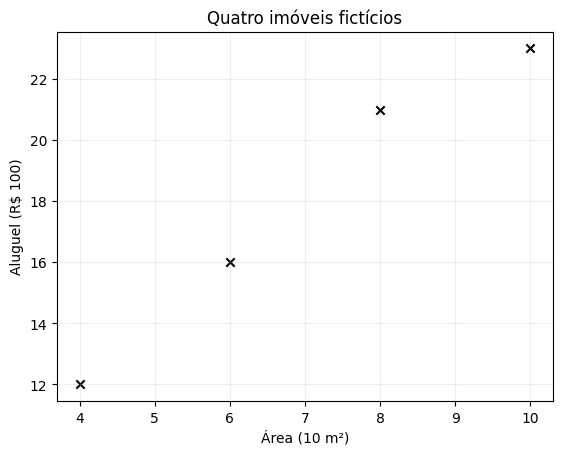

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
x = np.array([4., 6., 8., 10.])
y = np.array([12., 16., 21., 23.])
plt.scatter(x, y, marker='x', color='black')
plt.xlabel('Área (10 m²)'); plt.ylabel('Aluguel (R$ 100)')
plt.title('Quatro imóveis fictícios'); plt.grid(alpha=.2)
plt.show()

## 2. Função de custo — 7 minutos

$J(w,b)=\frac{1}{2m}\sum_i (wx_i+b-y_i)^2$.

Implemente a função e confira dois estados: $(0,0)$ e $(2,4)$. Qual deles produz a reta mais próxima dos dados?

In [ ]:
def calcular_custo(x, y, w, b):
    # TODO: previsão, erro, quadrado, média e fator 1/2
    raise NotImplementedError("Complete a função de custo")

print('J(0,0) =', calcular_custo(x,y,0.,0.))
print('J(2,4) =', calcular_custo(x,y,2.,4.))

## 3. Calcular o gradiente — 10 minutos

O erro é previsão menos alvo. A derivada em relação a $w$ usa a média de erro vezes entrada. A de $b$ usa a média dos erros. Calcule ambas com os mesmos parâmetros atuais.

Antes de executar, preveja o sinal de cada componente em $(0,0)$ e justifique.

In [ ]:
def calcular_gradiente(x, y, w, b):
    # TODO: calcular os dois gradientes com os mesmos w e b
    raise NotImplementedError("Complete os dois componentes do gradiente")

print('Gradiente inicial:', calcular_gradiente(x,y,0.,0.))

## 4. Uma atualização simultânea — 6 minutos

Implemente o passo. Use taxa 0,01 e os parâmetros iniciais zerados. Confira as previsões e o novo custo com a conta da aula.

In [ ]:
def dar_passo(x, y, w, b, alpha):
    # TODO: calcular ambos os gradientes antes de atualizar
    raise NotImplementedError("Complete a atualização simultânea")

w1,b1 = dar_passo(x,y,0.,0.,.01)
print('Primeiro estado:', w1,b1)
print('Previsões:',w1*x+b1)
print('Novo custo:',calcular_custo(x,y,w1,b1))

## 5. Treinar e ler três gráficos — 10 minutos

O histórico abaixo inclui o estado inicial em `t=0`. Há `passos+1` linhas e cada linha guarda `(w,b,custo)`. A linha `t=1` representa a primeira atualização.

Preveja se os dois parâmetros precisam crescer em todas as iterações. Depois examine os registros de 100 e de mil passos.

In [ ]:
def treinar(x, y, alpha=.01, passos=10000, w=0., b=0.):
    historico = [(w, b, calcular_custo(x,y,w,b))]
    for _ in range(passos):
        w,b = dar_passo(x,y,w,b,alpha)
        historico.append((w,b,calcular_custo(x,y,w,b)))
    return np.array(historico)

historico=treinar(x,y)
for t in [0,1,2,100,1000,10000]:
    print(f't={t:5d}: w={historico[t,0]:.6f}; b={historico[t,1]:.6f}; J={historico[t,2]:.9f}')

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(16,4),layout='constrained')
xx=np.linspace(3.5,10.5,100)
axes[0].scatter(x,y,c='black',marker='x',label='dados fictícios')
for t in [0,1,100,10000]:
    w,b,_=historico[t]
    axes[0].plot(xx,w*xx+b,label=f't={t}')
axes[0].set(xlabel='Área (10 m²)',ylabel='Aluguel (R$ 100)',title='Retas durante o treinamento')
axes[0].legend()
W,B=np.meshgrid(np.linspace(0,3,140),np.linspace(0,6,140))
J=sum((W*xi+B-yi)**2 for xi,yi in zip(x,y))/(2*len(x))
axes[1].contour(W,B,J,levels=[.23,.3,.5,1,3,10,40,100])
axes[1].plot(historico[:,0],historico[:,1],color='green',label='trajetória')
axes[1].scatter([1.9],[4.7],marker='*',c='black',label='ótimo')
axes[1].set(xlabel='w',ylabel='b',title='Plano dos parâmetros'); axes[1].legend()
axes[2].semilogy(np.arange(len(historico)),historico[:,2])
axes[2].axhline(.225,ls=':',color='gray',label='mínimo')
axes[2].set(xlabel='Atualizações realizadas t',ylabel='J (escala log)',title='Custo por iteração')
axes[2].legend();plt.show()

## 6. Taxas em uma função didática separada — 8 minutos

**Atenção:** $Q(w)=\frac12(w-3)^2$ não é o custo dos imóveis. Nesta função, a derivada é $w-3$. A partir de zero, compare as taxas 0,1; 0,8; 1,5; 2 e 2,2. Antecipe quais casos convergem, entram em ciclo ou divergem. Oscilar sempre significa divergir?

In [ ]:
def experimento_q(alpha, passos=12):
    valores = [0.]
    for _ in range(passos):
        w = valores[-1]
        valores.append(w - alpha * (w-3))
    return np.array(valores)

fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for alpha in [.1,.8,1.5,2.,2.2]:
    valores=experimento_q(alpha)
    axes[0].plot(valores,'o-',label=f'α={alpha:g}',ms=3)
    axes[1].semilogy(.5*(valores-3)**2,'o-',label=f'α={alpha:g}',ms=3)
axes[0].axhline(3,ls=':',color='black')
axes[0].set(xlabel='Atualizações t',ylabel='w',title='Parâmetros')
axes[1].set(xlabel='Atualizações t',ylabel='Q(w), escala log',title='Custo')
for ax in axes: ax.legend();ax.grid(alpha=.2)
plt.show()
print('α=2:',experimento_q(2,4))

## 7. As taxas não são universais — 5 minutos

Agora volte aos imóveis. Mantenha o mesmo início e compare 0,001, 0,01 e 0,04. Não transfira o intervalo de taxas da função $Q$ para este custo. Por que a curva crescente precisa ser diagnosticada?

In [ ]:
plt.figure(figsize=(9,4))
for alpha in [.001,.01,.04]:
    h=treinar(x,y,alpha=alpha,passos=200)
    plt.semilogy(np.arange(len(h)),h[:,2],label=f'α={alpha:g}')
plt.xlabel('Atualizações realizadas t');plt.ylabel('J, escala log')
plt.title('Comparar taxas nos quatro imóveis')
plt.legend();plt.grid(alpha=.2);plt.show()

## 8. Diagnosticar estados misturados — 5 minutos

A função abaixo altera $w$ e depois recalcula o gradiente de $b$ com esse novo valor. Compare-a com o primeiro passo correto. Explique o erro antes de executar. Não conclua que uma regra é a mesma só porque também reduz o custo.

In [ ]:
def passo_com_estados_misturados(x,y,w,b,alpha):
    g_w,_=calcular_gradiente(x,y,w,b)
    w=w-alpha*g_w
    _,g_b=calcular_gradiente(x,y,w,b)  # usa w já atualizado
    b=b-alpha*g_b
    return w,b

print('Simultâneo:',dar_passo(x,y,0.,0.,.01))
print('Estados misturados:',passo_com_estados_misturados(x,y,0.,0.,.01))

## 9. Previsão, evidências e entrega — 4 minutos

Use os parâmetros finais para prever o aluguel de 70 m² e converta a resposta para reais. Responda:

1. Por que os dois gradientes iniciais são negativos?
2. Qual é a primeira atualização e quanto caiu o custo?
3. Que evidência distingue oscilação convergente de divergência?
4. Como os passos podem diminuir com taxa fixa?
5. Por que o custo ótimo é positivo e por que isso não garante qualidade em dados novos?

Entregue o notebook executado e as respostas. Escreva as interpretações, não apenas os valores.

In [ ]:
w_final,b_final,custo_final=historico[-1]
previsao=w_final*7+b_final
print(f'w={w_final:.6f}; b={b_final:.6f}; J={custo_final:.9f}')
print(f'70 m²: {previsao:.6f} centenas de reais = R$ {100*previsao:.2f}')
print('Erros finais:',w_final*x+b_final-y)
print('Gradiente final:',calcular_gradiente(x,y,w_final,b_final))